# Phase 3 — External Capabilities

* Integrate Weather MCP.
* Build the custom Maps MCP.
* Integrate trvl MCP.
* Integrate TicketLens MCP.
* Evaluate the impact of external data on recommendations.

In [1]:
# Imports and environment setup

import os
import json
import uuid
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display, Markdown
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, ToolMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langchain_mcp_adapters.client import MultiServerMCPClient
from pydantic import BaseModel, Field

load_dotenv(override=True)

True

## IMPORTANT: Adjustment for Windows

The following adjustment is needed when running MCP servers via stdio inside a Jupyter notebook on Windows. Jupyter's stderr stream is not a regular file, which can cause the MCP Python SDK to fail when launching the server. This workaround redirects the server's error output to DEVNULL. On macOS and Linux, no adjustment is required.

In [2]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Applied the Windows adjustment


## MCP Servers

### Add Weather MCP

In [ ]:
# Not working in Jupyter Notebooks
client = MultiServerMCPClient({
    "weather": {
        "transport": "stdio",
        "command": "npx",
        "args": ["-y", "@dangahagan/weather-mcp@latest"]
    },
})

tools = await client.get_tools()

print(f"Loaded {len(tools)} weather tools:")
for t in tools:
    print(" -", t.name)

In [ ]:
# Alternative MCP for testing weather tools
mcp_client = MultiServerMCPClient(
    {
        "weather": {
            "transport": "stdio",
            "command": "npx",
            "args": [
                "-y",
                "@cyanheads/open-meteo-mcp-server@latest",
            ],
            "env": {
                "MCP_TRANSPORT_TYPE": "stdio",
                "MCP_LOG_LEVEL": "info",
            },
        }
    }
)

tools = await mcp_client.get_tools()

print(f"Loaded {len(tools)} weather tools:")

for t in tools:
    print(" -", t.name)

Loaded 11 weather tools:
 - openmeteo_search_locations
 - openmeteo_get_elevation
 - openmeteo_get_forecast
 - openmeteo_get_historical
 - openmeteo_get_marine
 - openmeteo_get_air_quality
 - openmeteo_get_ensemble
 - openmeteo_get_flood
 - openmeteo_get_climate
 - openmeteo_dataframe_query
 - openmeteo_dataframe_describe


### Add Activities MCP (TicketLens)

In [3]:
client = MultiServerMCPClient({
    "ticketlens": {
        "transport": "http",
        "url": "https://mcp.ticketlens.com/",
    }
})

tools = await client.get_tools()

print(f"Loaded {len(tools)} weather tools:")
for t in tools:
    print(f"{t.name}: {t.description}")

Loaded 5 weather tools:
submit_feedback: Share structured feedback with the TicketLens MCP creators when behavior is broken, confusing, missing, or worth improving.
search_tours: Search tour offers by query, POI, city, destination, price and tags
get_tour: Fetch canonical tour record by tour_id
search_pois: Resolve POI names, aliases, and possible candidates before tour search
health_check: Passive health snapshot for the MCP server


In [4]:
# Verify that the MCP is working
search_pois = next(
    t for t in tools
    if t.name == "search_pois"
)

result = await search_pois.ainvoke({
    "payload": {
        "query": "Eiffel Tower"
    }
})

print(result)

[{'type': 'text', 'text': '{\n  "pois": [\n    {\n      "id": "660851",\n      "name": "Eiffel Tower",\n      "aliases": [\n        "Eiffelturm",\n        "Torre Eiffel",\n        "Tour Eiffel"\n      ],\n      "city": null,\n      "country": null,\n      "destination_id": "5",\n      "distance_km": null,\n      "score": 1.0,\n      "confidence": "high"\n    },\n    {\n      "id": "12138269",\n      "name": "Eiffel Tower Las Vegas",\n      "aliases": [\n        "Eiffel Tower"\n      ],\n      "city": null,\n      "country": null,\n      "destination_id": "120",\n      "distance_km": null,\n      "score": 1.0,\n      "confidence": "high"\n    }\n  ],\n  "resolved_exact": true,\n  "suggestions": [\n    "Eiffel Tower",\n    "Eiffel Tower Las Vegas"\n  ],\n  "did_you_mean": null,\n  "request_id": "143421d3-a9d7-4e32-b9c2-7b2e3eb410fc"\n}', 'id': 'lc_f25fde9f-36d3-4b83-9bd4-a0ccdcb5229e'}]


In [5]:
# Only keep tools that are relevant to the agent
ticketlens_tool_names = {"search_pois", "search_tours", "get_tour"}

ticketlens_tools = [
    t for t in tools
    if t.name in ticketlens_tool_names
]

## Integrate MCPs into the Travel Planner Agent

### Define the shared `TravelState`

In [6]:
# Define the shared TravelState
class TravelRequirements(BaseModel):
    origin: str | None = None
    destination: str | None = None
    travel_dates: str | None = None
    duration_days: int | None = None
    travelers: int | None = None
    budget: float | None = None
    currency: str | None = None
    interests: list[str] = Field(default_factory=list)
    constraints: list[str] = Field(default_factory=list)

class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None

### Tool for updating the travel state

In [9]:
# Auxliary functions for update_requirements tool
def normalize_list(value: list[str] | str | None) -> list[str]:
    """
    Normalize a value into a list of strings.

    Accepts None, an existing list, or a JSON-encoded list returned as a string.
    If the string is not valid JSON, it is treated as a single list item.
    """
    if value is None:
        return []

    if isinstance(value, list):
        return value

    # The model may return the list as a JSON-encoded string.
    if isinstance(value, str):
        try:
            parsed = json.loads(value)

            # Return the parsed value if it is a valid JSON list.
            if isinstance(parsed, list):
                return parsed

        except json.JSONDecodeError:
            pass

        return [value]

    # Fallback for unexpected input types.
    return []

In [10]:
@tool
def update_requirements(
    runtime: ToolRuntime,
    origin: str | None = None,
    destination: str | None = None,
    travel_dates: str | None = None,
    duration_days: int | None = None,
    travelers: int | None = None,
    budget: float | None = None,
    currency: str | None = None,
    add_interests: list[str] | str | None = None,
    remove_interests: list[str] | str | None = None,
    add_constraints: list[str] | str | None = None,
    remove_constraints: list[str] | str | None = None,
) -> Command:
    """
    Update the user's current travel requirements.

    Only provide fields that have been explicitly added or changed by the user.

    For interests and constraints:
    - Use add_interests to add new interests.
    - Use remove_interests to remove previous interests.
    - Use add_constraints to add new constraints.
    - Use remove_constraints to remove previous constraints.

    Do not invent requirements or modify information that the user has not
    explicitly changed.
    """

    # ToolRuntime gives the tool access to the current LangGraph state,
    # including the TravelRequirements stored in the current graph execution.
    current = runtime.state["requirements"]

    if current is None:
        current = TravelRequirements()

    updated = current.model_copy()

    # Normalize list arguments in case the model sends JSON strings.
    add_interests = normalize_list(add_interests)
    remove_interests = normalize_list(remove_interests)
    add_constraints = normalize_list(add_constraints)
    remove_constraints = normalize_list(remove_constraints)

    # Update scalar fields only when explicitly provided
    if origin is not None:
        updated.origin = origin

    if destination is not None:
        updated.destination = destination

    if travel_dates is not None:
        updated.travel_dates = travel_dates

    if duration_days is not None:
        updated.duration_days = duration_days

    if travelers is not None:
        updated.travelers = travelers

    if budget is not None:
        updated.budget = budget

    if currency is not None:
        updated.currency = currency

    # Update interests
    if add_interests:
        updated.interests = list(
            dict.fromkeys(
                updated.interests + add_interests
            )
        )

    if remove_interests:
        updated.interests = [
            interest
            for interest in updated.interests
            if interest not in remove_interests
        ]

    # Update constraints
    if add_constraints:
        updated.constraints = list(
            dict.fromkeys(
                updated.constraints + add_constraints
            )
        )

    if remove_constraints:
        updated.constraints = [
            constraint
            for constraint in updated.constraints
            if constraint not in remove_constraints
        ]

    # Command tells LangGraph to update the graph state.
    # The new TravelRequirements replaces the current "requirements" value.
    return Command(
        update={
            "requirements": updated,
            "messages": [
                ToolMessage(
                    content="Travel requirements updated successfully.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )

### Travel Planner with requirements update tool + MCP

In [11]:
SYSTEM_PROMPT = """
You are a Travel Planner specialized in helping users design personalized trips.

Your goal is to understand the user's travel preferences and constraints and
help them make informed travel decisions.

Your personality is:
- Helpful and practical
- Clear and concise
- Curious about the user's preferences
- Honest about uncertainty
- Proactive when additional information would improve the recommendation

When planning a trip:
- Consider the user's stated preferences and constraints carefully.
- Ask for clarification when essential information is missing.
- Do not invent specific facts, prices, availability, or other real-world data.
- Explain the reasoning behind important recommendations.
- Prioritize the user's requirements rather than suggesting generic popular destinations.

When updating the travel state:
- Treat the current travel requirements as the current state of the trip.
- Use the update_requirements tool when the user adds, changes, removes, or reverses a travel requirement.
- Only update information explicitly provided by the user.
- Preserve requirements that have not changed.
- If the user withdraws or contradicts a previous requirement, remove or replace the previous requirement.
- When requirements conflict, prioritize the user's latest explicit instruction.

Tools:
- Use external tools when they can provide relevant, specific information  for the user's request.
- Prefer tool results over general knowledge when answering questions that depend on external or current information.
- Do not claim that you searched for or verified information unless a tool actually returned it.
- Use the minimum number of tools necessary to answer the user's request.
- If a tool cannot provide the requested information, be transparent about the limitation rather than inventing an answer.

Scope:
- Only answer questions related to travel planning and your capabilities.
- If the user asks about something outside your scope, briefly explain that you cannot help with it.

When using external travel data:
- Clearly distinguish information obtained from tools from general knowledge.
- Do not assume that tool results guarantee current prices or availability unless the tool explicitly provides that information.
"""

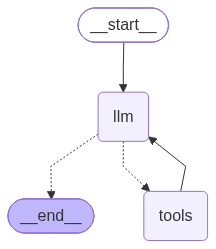

In [12]:
# ---- LLM Node ----
llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

# Add tools to the LLM, including the ones from MCPs
tools = [update_requirements, *ticketlens_tools]
llm_with_tools = llm.bind_tools(tools)

def llm_node(state: TravelState) -> dict:
    # Extract the current requirements from the state
    current_requirements = state["requirements"]
    requirements_context = SystemMessage(
        content=f"""
Current travel requirements:

{current_requirements}
"""
    )

    # Add the current requirements to the system prompt + messages
    messages = [
        SystemMessage(content=SYSTEM_PROMPT),
        requirements_context, 
        *state["messages"],
    ]

    response = llm_with_tools.invoke(messages)

    return {"messages": [response]}

# ---- Graph Builder ----
# Add short-term memory checkpointing
checkpointer = InMemorySaver()

builder = StateGraph(TravelState)

builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

graph = builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))

## Test with different prompts

In [19]:
async def test_prompt(prompt):
    config = {"configurable": {"thread_id": str(uuid.uuid4())}}

    result = await graph.ainvoke({
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "requirements": None
    }, config)

    response = result["messages"][-1].content
    display(Markdown(response))

    return result

Verify the agent's traces with LangSmith: https://smith.langchain.com

### 1. Activities MCP

In [20]:
# Test search_pois tool
prompt1 = "I'm planning a trip to Paris. Can you find the main points of " \
    "interest around the Eiffel Tower?"
test1 = await test_prompt(prompt1)

Based on my search for tours and general knowledge, here are the main points of interest around the Eiffel Tower in Paris:

**Immediate Vicinity:**
- **Champ de Mars** - The large public greenspace directly in front of the Eiffel Tower, perfect for picnics and photos
- **Trocadéro & Jardins du Trocadéro** - Across the Seine, offers the most iconic viewpoint of the Eiffel Tower
- **Palais de Chaillot** - Historic building at Trocadéro with excellent viewing platforms

**Nearby Attractions:**
- **Seine River** - River cruises depart from nearby docks (many tours combine Eiffel Tower with Seine cruises)
- **Musée du Quai Branly - Jacques Chirac** - Indigenous art museum just a short walk away
- **Invalides & Musée de l'Armée** - The golden-domed building is visible from the tower and contains Napoleon's tomb

**Dining & Experiences:**
- **Madame Brasserie** - Restaurant located within the Eiffel Tower itself (I found several tour options for dining here)
- **Picnic on Champ de Mars** - Popular with both tourists and locals

**Additional Considerations:**
- The area is well-connected by metro (Bir-Hakeim, Trocadéro stations)
- Evening visits offer spectacular views of Paris illuminated
- Many combination tours include Eiffel Tower access with other Paris highlights

To help you plan more effectively, could you share:
1. When are you planning to visit? (dates or general season)
2. How long do you want to spend in Paris?
3. Any particular interests beyond sightseeing? (art, history, food, etc.)
4. Budget range for activities?
5. Will you be traveling alone or with others?

This information will help me provide more tailored recommendations and find specific tours or experiences that match your preferences.

In [21]:
test1["requirements"]

TravelRequirements(origin=None, destination='Paris, France', travel_dates=None, duration_days=None, travelers=None, budget=None, currency=None, interests=[], constraints=[])

**Good response**: Checking LangSmith traces, the agent called `search_pois` and `search_tours` later. 

In [23]:
# Test search_tours tool
prompt2 = "I'm going to Paris and I'm interested in guided tours or experiences" \
    " related to the Eiffel Tower. What options can you find?"
test2 = await test_prompt(prompt2)

Based on your interest in Eiffel Tower guided tours in Paris, I found several options. Here are some of the top-rated tours:

## Top Eiffel Tower Guided Tours

1. **Paris: Eiffel Tower Guided Tour and Seine River Cruise**
   - Price: €69 (approx $67 USD, £50 GBP)
   - Rating: 4.5/5 (241 reviews)
   - Combines tower access with a river cruise
   - First available: August 26, 2026

2. **Paris: Eiffel Tower Guided Tour by Elevator**
   - Price: €53 (approx $63 USD, £46 GBP)
   - Rating: 4.3/5 (43 reviews)
   - Focuses on elevator access to the tower
   - First available: August 25, 2026

3. **Eiffel Tower Paris: Official guided tour in virtual reality**
   - Price: €29 (approx $33 USD, £25 GBP)
   - Rating: 4.9/5 (151 reviews) - Highest rated!
   - Unique virtual reality experience at the tower
   - First available: August 25, 2026

4. **Paris: Eiffel Tower Fully Guided Tour with Summit Option**
   - Price: €50 (approx $58 USD, £43 GBP)
   - Rating: 4.3/5 (833 reviews) - Most reviewed!
   - Offers option to visit the summit
   - First available: August 25, 2026

5. **Paris: Eiffel Tower Summit Small-Group Guided Tour Max 6 People**
   - Price: €116 (approx $138 USD, £101 GBP)
   - Rating: 4.95/5 (124 reviews) - Premium small-group experience
   - Limited to 6 people for more personalized attention
   - First available: August 25, 2026

There are also combination tours that include other Paris attractions like Versailles Palace or the Louvre, as well as full-day tours covering multiple sites.

**To help you choose the best option, could you tell me:**
- Do you have specific travel dates in mind?
- What's your budget range for this experience?
- Would you prefer a private tour or are you comfortable in a group setting?
- Are you interested in summit access or would a second-floor view be sufficient?

You can also click on any of the tour links above for more detailed information about inclusions, schedules, and what's covered in each tour.

The agent correctly used the `search_tours` tool and returned precise results for different tours.

In [24]:
# Test get_tour tool
prompt3 = "Find me a tour in Paris related to the Eiffel Tower and then give me more details about one of the available options."
test3 = await test_prompt(prompt3)

I found several Eiffel Tower tours in Paris! Here's an overview of the available options, followed by detailed information about one of the most popular choices:

---

## 🗼 Available Eiffel Tower Tours in Paris

| # | Tour | Price (EUR) | Rating | Reviews |
|---|------|-------------|--------|---------|
| 1 | Eiffel Tower: Official guided tour in virtual reality | €29 | ⭐ 4.93 | 151 |
| 2 | Eiffel Tower & Parisian Bridges Private Photo Tour | €155 | ⭐ 3.00 | 1 |
| 3 | **Eiffel Tower Access by Elevator & Seine River Cruise** | **€69** | **⭐ 4.56** | **7,642** |
| 4 | Early Evening Dinner at Madame Brasserie | €129.80 | ⭐ 4.46 | 1,683 |
| 5 | Stairs Climb to Level 2 & Summit Option | €39 | ⭐ 4.22 | 9,812 |
| 6 | Summit or Second Floor Access | €51.62 | ⭐ 4.42 | 17,092 |
| 7 | Eiffel Tower Tour & Seine River Cruise Tour | €66 | ⭐ 4.27 | 291 |
| 8 | Madame Brasserie 3-Course Lunch | €70.80 | ⭐ 4.31 | 2,611 |
| 9 | Fully Guided Tour with Summit Option | €50 | ⭐ 4.30 | 833 |
| 10 | E-Bike Night Tour (Eiffel Tower & Notre Dame) | €99 | ⭐ 4.94 | 16 |

---

## 🏆 Detailed Tour: Paris: Eiffel Tower Access by Elevator & Seine River Cruise

This is one of the best-rated combo tours with over 7,600 reviews!

### 💰 Price
- **€69** (~$80 USD / ~£59 GBP / ~65 CHF)

### ⭐ Rating
- **4.56/5** from 7,642 reviews

### 📋 What's Included
- ✅ Reserved entry to the 1st and 2nd floor of the Eiffel Tower
- ✅ Standard access to the summit (optional upgrade)
- ✅ 1-hour Seine River cruise
- ✅ Skip-the-line access
- ✅ English-speaking guide intro commentary
- ✅ Unlimited time inside the Eiffel Tower

### ❌ Not Included
- Gratuities
- Transfers
- Food and drink

### 📍 Meeting Point
**Agency at 41 Avenue de la Bourdonnais, 75007 Paris**
- Office hours: 08:30 – 18:30, daily

### 🚢 Cruise Schedule
- **October – March:** Departures every hour (10:00 – 21:30)
- **April – September:** Departures every 30 minutes (10:00 – 21:30)

### ⚠️ Important Information
- Arrive 15 minutes before your chosen time slot
- Children under 3 enter free (with valid ID)
- No large luggage allowed (no storage available)
- Summit may close due to weather/maintenance
- Not wheelchair accessible
- Cruise tickets valid for 6 months after your Eiffel Tower visit

---

**Would you like me to:**
1. Search for more specific tour types (e.g., private tours, food tours, photography tours)?
2. Help you plan the rest of your Paris trip?
3. Get more details on any other tour from the list?

The agent answered successfully the user's request. First, it called `search_tools` and then `get_tour` for getting detailed information about the best tour.